<a href="https://colab.research.google.com/github/LexieLyu37/also-cracker/blob/main/03_ML_NLFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CID: 02392139 Username: kl3323

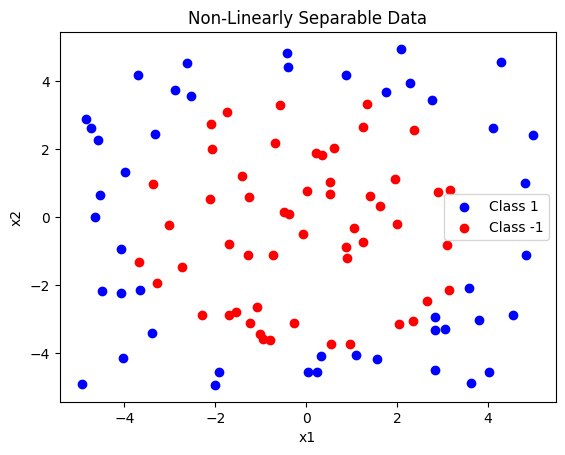

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def generate_non_linearly_separable_data(num_samples, random_seed=32):
    # Set the random seed for consistent data generation
    np.random.seed(random_seed)
    # Generate random data points for x1 and x2 in the range [-5, 5]
    x1 = np.random.uniform(-5, 5, num_samples)
    x2 = np.random.uniform(-5, 5, num_samples)

    # Assign labels such that the data points are not linearly separable
    labels = np.where(x1**2 + x2**2 >= 16, 1, -1)

    return x1, x2, labels

def plot_data(x1, x2, labels, title):
    # Plot the data points with different colors for each class
    plt.scatter(x1[labels==1], x2[labels==1], c='b', marker='o', label='Class 1')
    plt.scatter(x1[labels==-1], x2[labels==-1], c='r', marker='o', label='Class -1')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.title(title)
    plt.show()

num_samples_per_class = 50  # Half of the samples for each class
x1, x2, labels = generate_non_linearly_separable_data(num_samples_per_class * 2)

# Stack the data in one numpy array to distinguish them from the tranformed data later on

X_original = np.column_stack((x1, x2))

# Plot non-linearly separable data
plot_data(x1, x2, labels, 'Non-Linearly Separable Data')

In [58]:
# PLA code below

def predict(W, X):
        """ Return class label after each setp """
        return np.where(net_input(W, X) >= 0.0, 1, -1)

def net_input(W, X):
        """ Calculate net input """
        return np.dot(X, W[1:]) + W[0]

def plot_boundary(W, X, y):
    """Function to plot the boundary defined by the weights. Given equation."""
    """w0 + w1*x1 + w2*x2 = 0, used to generate the line."""

    # Calculate the slope and y-intercept of the boundary line
    slope = -W[1] / W[2]
    intercept = -W[0] / W[2]

    # Get the minimum and maximum x values from the dataset
    x_min = np.min(X[:, 0])
    x_max = np.max(X[:, 0])

    # Generate points for the boundary line to cover the whole plot
    x_vals = np.array([x_min, x_max])
    y_vals = slope * x_vals + intercept

    # This part here define the x-axis and y-axis style according to the data we are using
    plt.scatter(X[y==1, 0], X[y==1, 1], c='b', marker='o', label='Class 1')
    plt.scatter(X[y==-1, 0], X[y==-1, 1], c='r', marker='o', label='Class -1')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.title('title')

    # Plot the line using the calculated points
    plt.plot(x_vals, y_vals, 'black')

    plt.show()

def plot_errors(error):
    plt.plot(range(1, len(error) + 1), error,marker='o')
    plt.xlabel('Iterations')
    plt.ylabel('Number of misclassifications')
    # Set the x-axis ticks to display only integer values
    # Set the x-axis ticks to be automatically determined based on available space
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

def pla(n_iter, X, y):
        W = np.zeros(1 + X.shape[1])
        errors_ = []
        for i in range(n_iter):
            for j, (xi, target) in enumerate(zip(X,y)):
         #     update = target - predict(W, xi)
         #     W += 0.5*update*np.append(1,xi)
              if predict(W, xi) != target:
                  W = W + target * np.append(1,xi)
            # errors on whole dataset
            errors = 0
            for j, (xi, target) in enumerate(zip(X, y)):
                if predict(W, xi) != target:
                    errors += 1
            # -------------------------------------------
            errors_.append(errors)
            i += 1
            print ("Iteration: ", i)
            print("Weights: ", W)
            print("Misclassified Samples: ", errors)
            plot_boundary(W,X,y)  #When weights are updated we plot the boundary

        plot_errors(errors_)

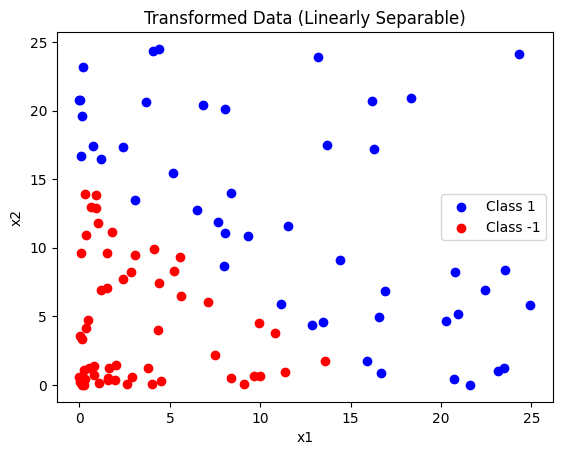

In [59]:
# Task 1
def transform(x1, x2):
    """Square each feature. This turns the circular boundary
    x1^2 + x2^2 = 16 into a straight line boundary z1 + z2 = 16."""
    z1 = x1**2
    z2 = x2**2
    return z1, z2

x1_transformed, x2_transformed = transform(x1, x2)
Z = np.column_stack((x1_transformed, x2_transformed))

plot_data(x1_transformed, x2_transformed, labels, 'Transformed Data (Linearly Separable)')

Iteration: 1, Weights: [-17.           9.68524052   8.43610346], Misclassified Samples: 45


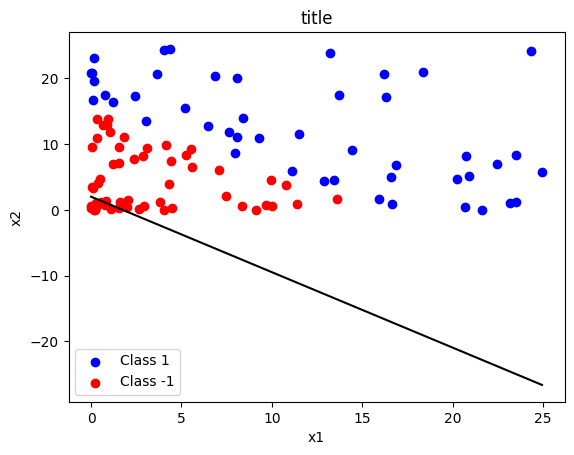

Iteration: 2, Weights: [-31.           1.75299895  16.10454318], Misclassified Samples: 30


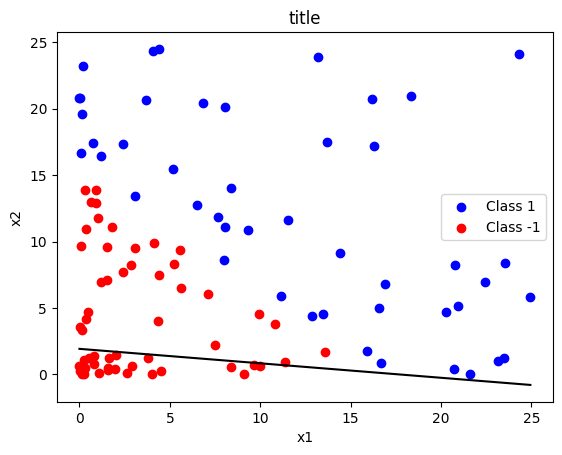

Iteration: 3, Weights: [-42.           2.75332963  19.90039811], Misclassified Samples: 30


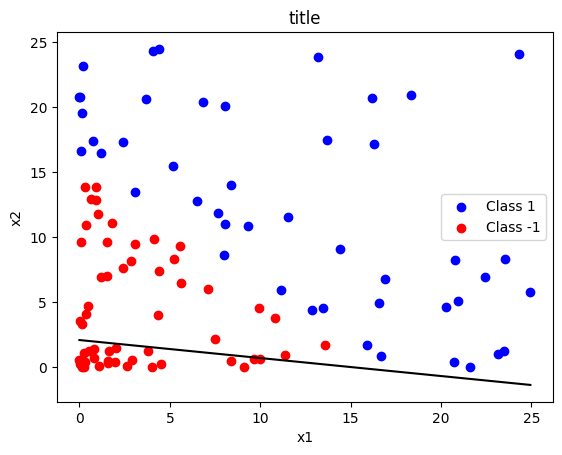

Iteration: 4, Weights: [-53.           4.56980444  11.74446629], Misclassified Samples: 27


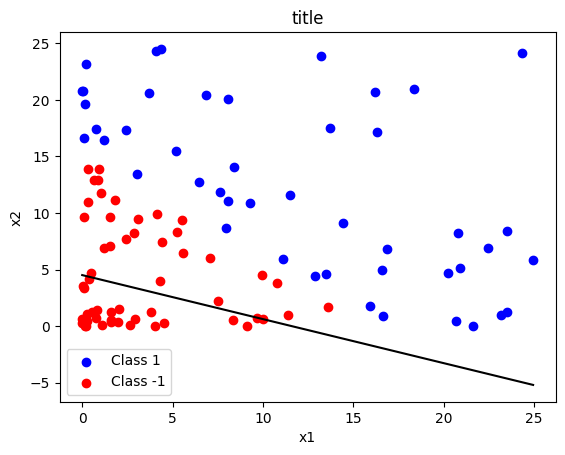

Iteration: 5, Weights: [-64.           9.66400388  20.14670934], Misclassified Samples: 34


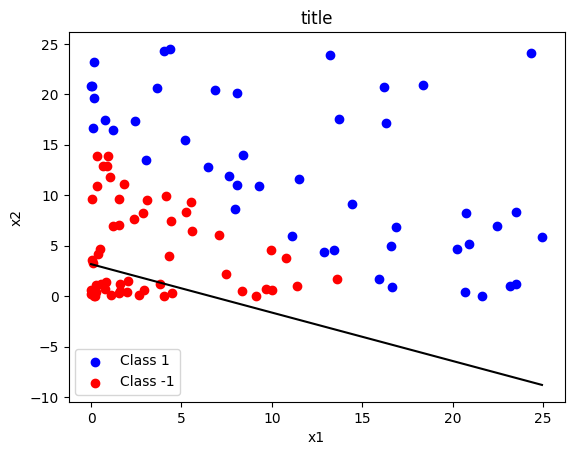

Iteration: 6, Weights: [-75.          -0.72575143  11.58179779], Misclassified Samples: 33


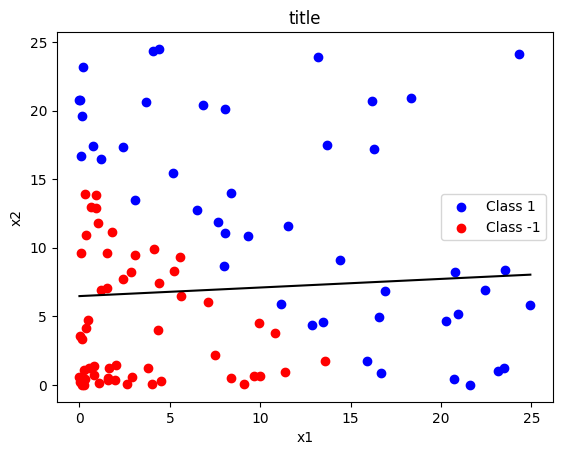

Iteration: 7, Weights: [-83.          12.91339811  14.07118694], Misclassified Samples: 30


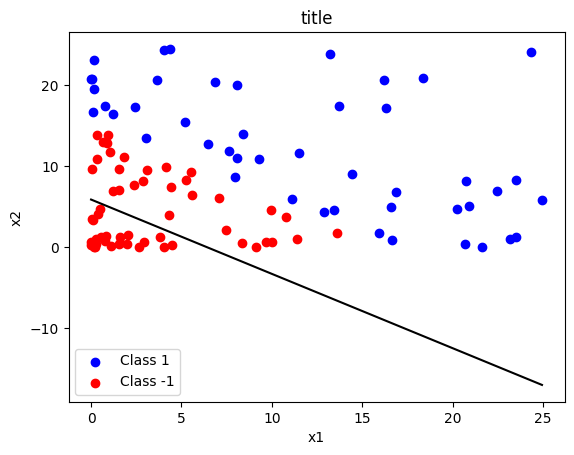

Iteration: 8, Weights: [-93.           6.49194458  18.98925636], Misclassified Samples: 24


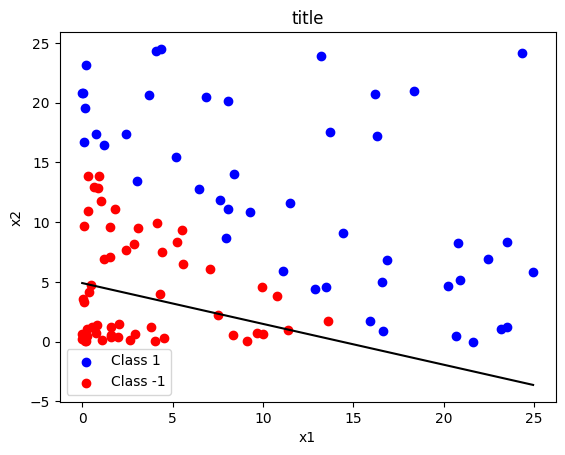

Iteration: 9, Weights: [-102.            2.90826368   12.67661856], Misclassified Samples: 24


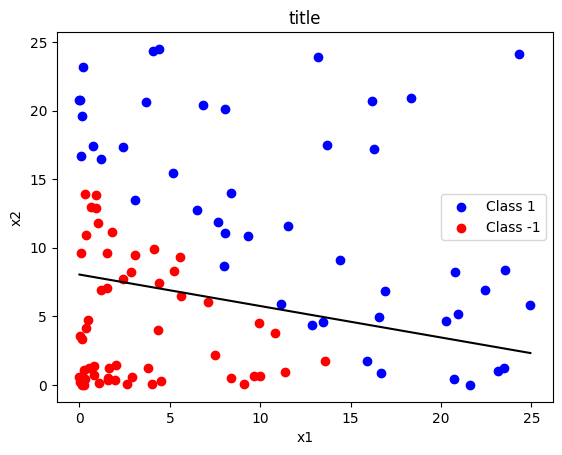

Iteration: 10, Weights: [-106.            1.82917854   11.72373476], Misclassified Samples: 25


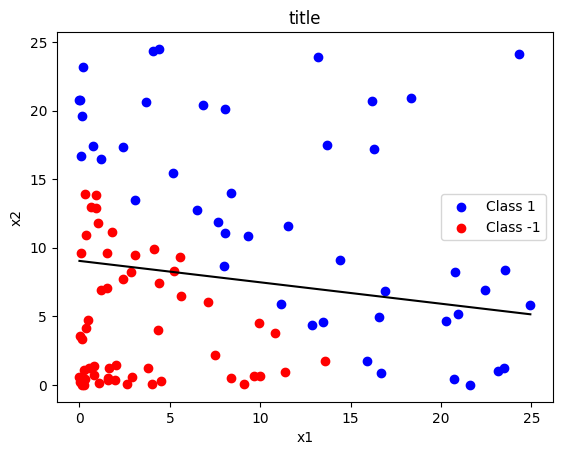

Iteration: 11, Weights: [-111.            3.24085336    9.18260464], Misclassified Samples: 17


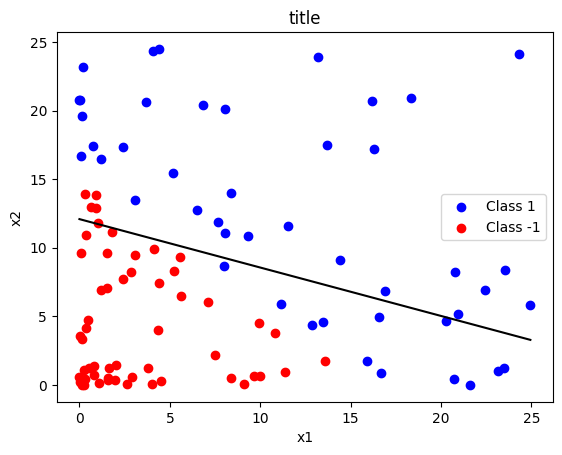

Iteration: 12, Weights: [-114.            1.9359373    11.72041527], Misclassified Samples: 24


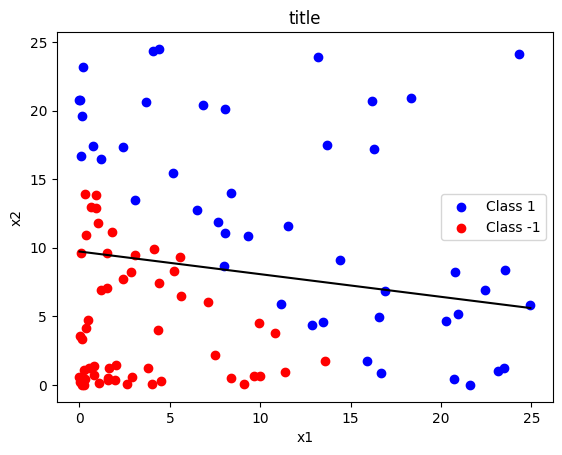

Iteration: 13, Weights: [-123.            3.12784839   10.20239119], Misclassified Samples: 19


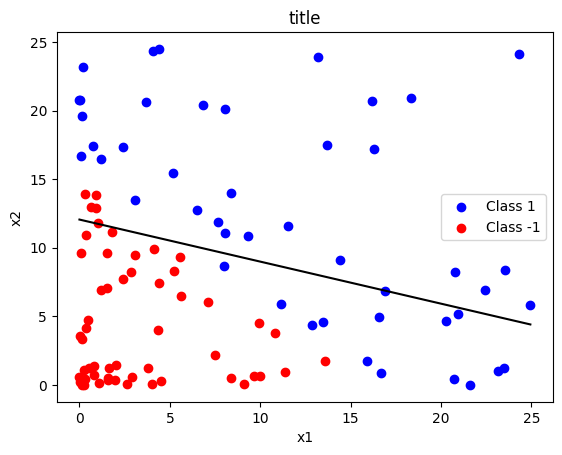

Iteration: 14, Weights: [-129.           16.28593814   20.38227144], Misclassified Samples: 30


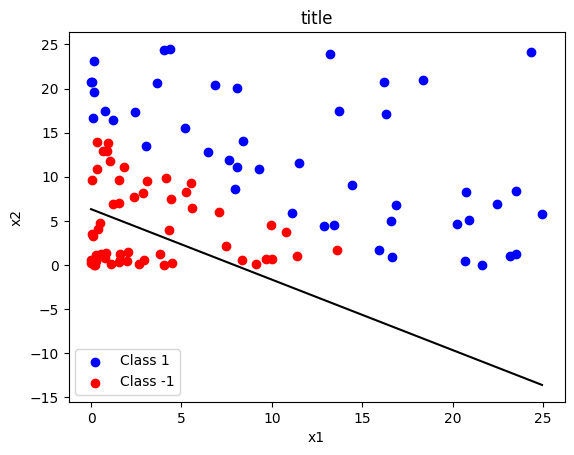

Iteration: 15, Weights: [-135.            5.00638588    9.5437171 ], Misclassified Samples: 12


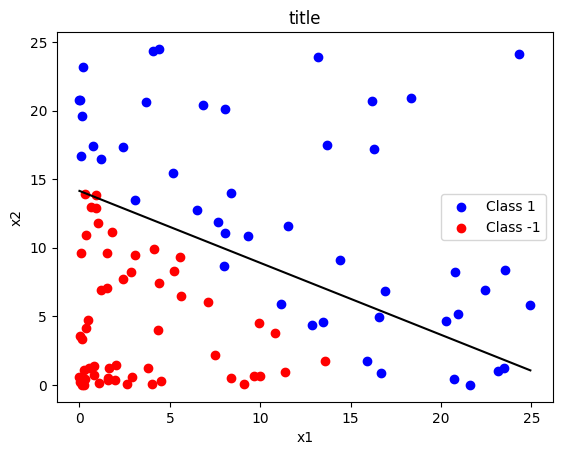

Iteration: 16, Weights: [-137.            8.10810749    8.70700393], Misclassified Samples: 0


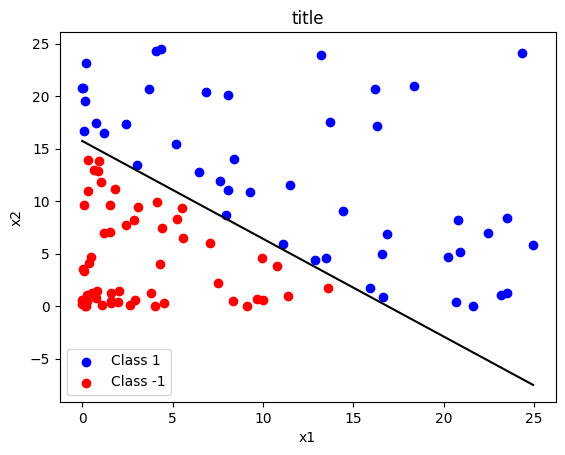

Iteration: 17, Weights: [-137.            8.10810749    8.70700393], Misclassified Samples: 0


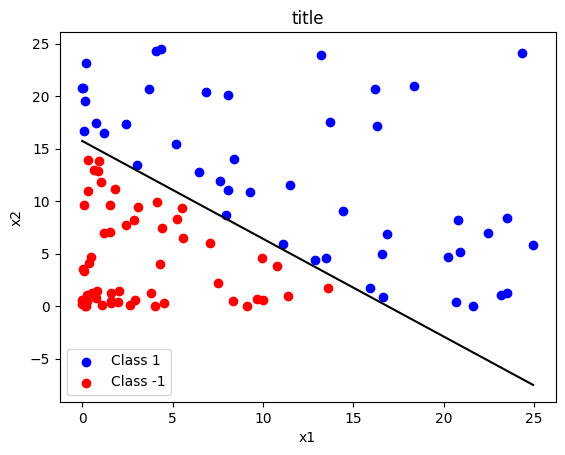

Iteration: 18, Weights: [-137.            8.10810749    8.70700393], Misclassified Samples: 0


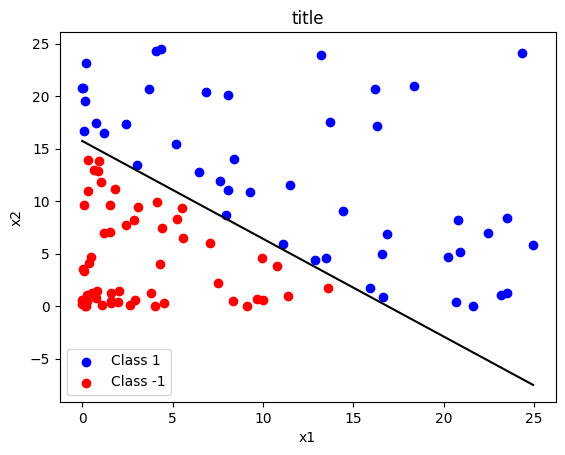

Iteration: 19, Weights: [-137.            8.10810749    8.70700393], Misclassified Samples: 0


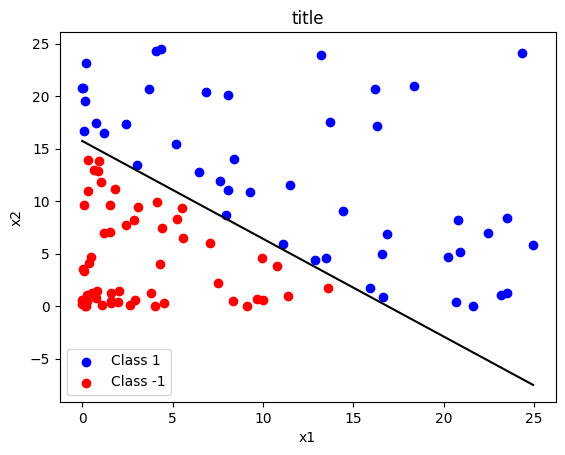

Iteration: 20, Weights: [-137.            8.10810749    8.70700393], Misclassified Samples: 0


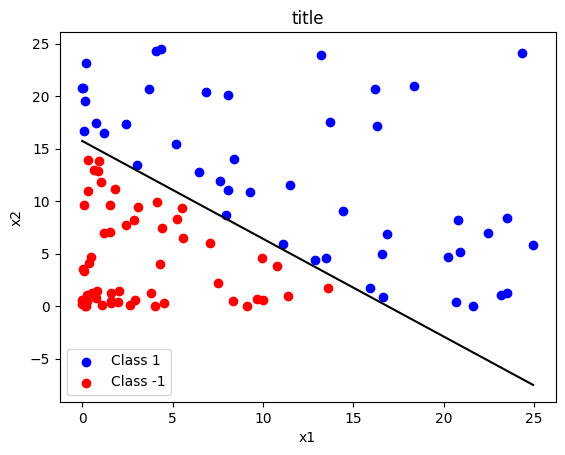

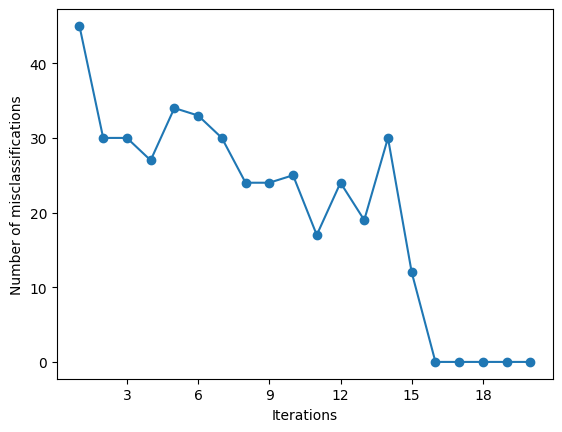


Final weights: [-137.            8.10810749    8.70700393]
Correctly classified samples: 100 out of 100
PLA achieved perfect classification at iteration: 16


In [60]:
# Task 1 (continued)
def pla_track(n_iter, X, y):
    """Same logic as pla(), but also returns the final weights,
    the error history, and the first iteration with 0 misclassifications."""
    W = np.zeros(1 + X.shape[1])
    errors_ = []
    perfect_iter = None
    for i in range(n_iter):
        for xi, target in zip(X, y):
            if predict(W, xi) != target:
                W = W + target * np.append(1, xi)
        errors = sum(predict(W, xi) != target for xi, target in zip(X, y))
        errors_.append(errors)
        if errors == 0 and perfect_iter is None:
            perfect_iter = i + 1
        print(f"Iteration: {i+1}, Weights: {W}, Misclassified Samples: {errors}")
        plot_boundary(W, X, y)
    plot_errors(errors_)
    return W, errors_, perfect_iter

n_iter = 20
W_final, errors_history, perfect_iter = pla_track(n_iter, Z, labels)

print(f"\nFinal weights: {W_final}")
print(f"Correctly classified samples: {len(labels) - errors_history[-1]} out of {len(labels)}")
print(f"PLA achieved perfect classification at iteration: {perfect_iter}")

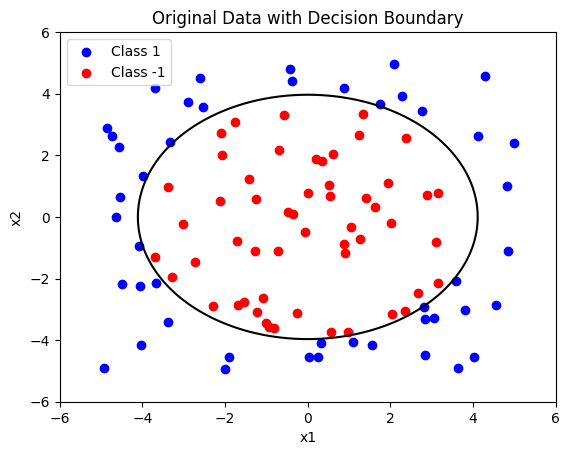

In [61]:
# Task 1 (continued)
xx1, xx2 = np.meshgrid(np.linspace(-6, 6, 300), np.linspace(-6, 6, 300))
zz = W_final[0] + W_final[1]*xx1**2 + W_final[2]*xx2**2

plt.scatter(x1[labels==1], x2[labels==1], c='b', marker='o', label='Class 1')
plt.scatter(x1[labels==-1], x2[labels==-1], c='r', marker='o', label='Class -1')
plt.contour(xx1, xx2, zz, levels=[0], colors='black')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.title('Original Data with Decision Boundary')
plt.show()

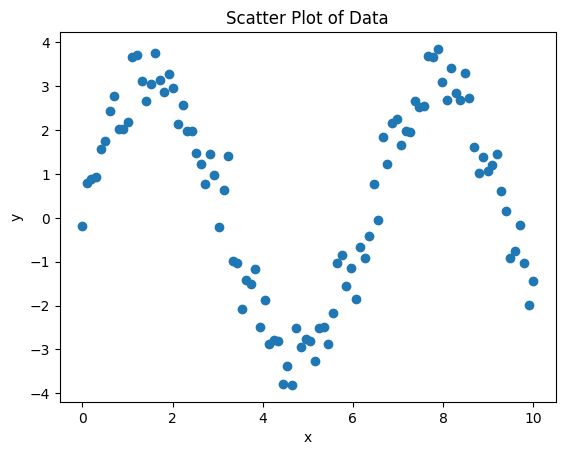

In [62]:
np.random.seed(32)  # Set a seed for reproducibility

# Generate data points with a sine-like pattern and noise
x = np.linspace(0, 10, 100)
y = 3 * np.sin(x) + np.random.normal(0, 0.5, 100)

# Plot the data
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter Plot of Data')
plt.show()

In [63]:
# Task 2
def polynomial_features(x, d, include_bias=True):
    """Transform a single feature x into polynomial features up to degree d.
    If include_bias=True: returns [1, x, x^2, ..., x^d]
    If include_bias=False: returns [x, x^2, ..., x^d]"""
    x = np.array(x).reshape(-1, 1)
    powers = range(0 if include_bias else 1, d + 1)
    Z = np.column_stack([x.flatten()**p for p in powers])
    return Z

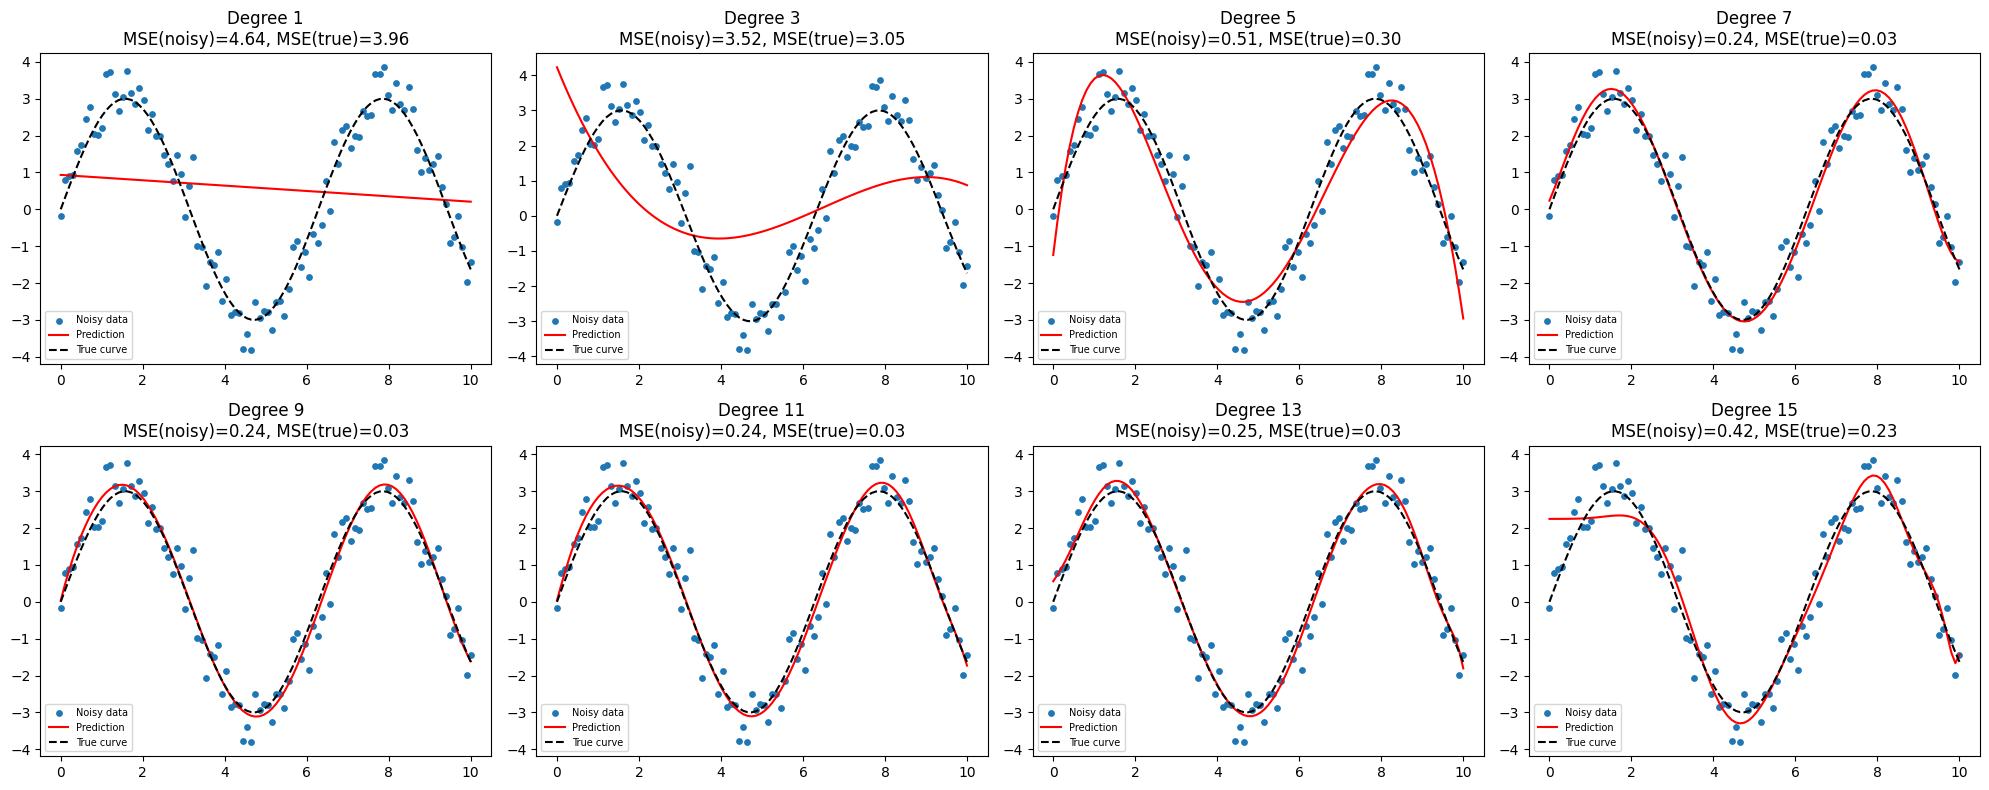

In [64]:
# Task 2 (continued)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

degrees = [1, 3, 5, 7, 9, 11, 13, 15]
true_curve = 3 * np.sin(x)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for idx, d in enumerate(degrees):
    Z = polynomial_features(x, d, include_bias=False)

    reg = LinearRegression()
    reg.fit(Z, y)
    y_pred = reg.predict(Z)

    mse_noisy = mean_squared_error(y, y_pred)
    mse_true = mean_squared_error(true_curve, y_pred)

    ax = axes[idx]
    ax.scatter(x, y, s=15, label='Noisy data')
    ax.plot(x, y_pred, color='red', label='Prediction')
    ax.plot(x, true_curve, 'k--', label='True curve')
    ax.set_title(f"Degree {d}\nMSE(noisy)={mse_noisy:.2f}, MSE(true)={mse_true:.2f}")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

In [65]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Copy of 03_ML_NLFT.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Copy of 03_ML_NLFT.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 26 image(s).
[NbConvertApp] Writing 1379993 bytes to /content/drive/MyDrive/Colab Notebooks/Copy of 03_ML_NLFT.html
